In [12]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import sklearn
import nltk

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NLTK:", nltk.__version__)

print("\nAll libraries imported successfully!")

Python: 3.14.10
Pandas: 3.1.1
NumPy: 2.5.5
Matplotlib: 3.11.2
Scikit-learn: 1.9.1
NLTK: 3.10.4

All libraries imported successfully!


In [2]:
from sklearn.metrics import accuracy_score

# Sample true labels
y_true = [
    "positive",
    "negative",
    "positive",
    "negative",
    "positive",
    "negative"
]

# Sample predicted labels
y_pred = [
    "positive",
    "negative",
    "negative",
    "negative",
    "positive",
    "positive"
]

# Calculate accuracy
accuracy = accuracy_score(y_true, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Accuracy: 0.6666666666666666
Accuracy Percentage: 66.66666666666666 %


In [3]:
from sklearn.metrics import precision_score

# Calculate precision for positive class
precision = precision_score(
    y_true,
    y_pred,
    pos_label="positive"
)

print("Precision:", precision)
print("Precision Percentage:", precision * 100, "%")

Precision: 0.6666666666666666
Precision Percentage: 66.66666666666666 %


In [4]:
from sklearn.metrics import recall_score

# Calculate recall for positive class
recall = recall_score(
    y_true,
    y_pred,
    pos_label="positive"
)

print("Recall:", recall)
print("Recall Percentage:", recall * 100, "%")

Recall: 0.6666666666666666
Recall Percentage: 66.66666666666666 %


In [5]:
from sklearn.metrics import f1_score

# Calculate F1-score for positive class
f1 = f1_score(
    y_true,
    y_pred,
    pos_label="positive"
)

print("F1-score:", f1)
print("F1-score Percentage:", f1 * 100, "%")

F1-score: 0.6666666666666666
F1-score Percentage: 66.66666666666666 %


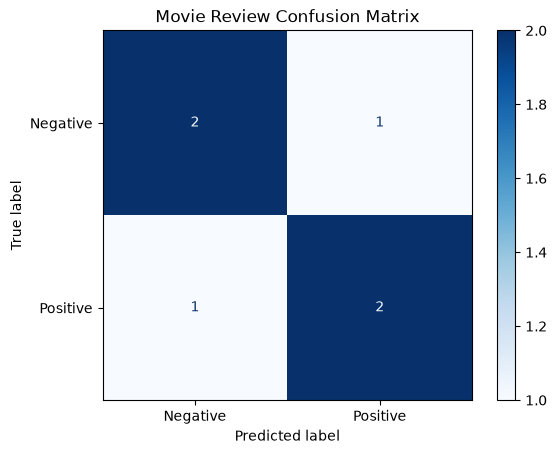

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=["negative", "positive"]
)

# Display confusion matrix
cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

cm_display.plot(cmap="Blues", values_format="d")

plt.title("Movie Review Confusion Matrix")
plt.show()

In [7]:
from sklearn.metrics import classification_report

# Generate detailed classification report
report = classification_report(
    y_true,
    y_pred,
    labels=["negative", "positive"],
    target_names=["Negative", "Positive"],
    zero_division=0
)

print(report)

              precision    recall  f1-score   support

    Negative       0.67      0.67      0.67         3
    Positive       0.67      0.67      0.67         3

    accuracy                           0.67         6
   macro avg       0.67      0.67      0.67         6
weighted avg       0.67      0.67      0.67         6



In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def evaluate_predictions(predictions, model_name):

    # Check empty data
    if predictions.empty:
        raise ValueError("No prediction data found!")

    # Check required columns
    required_columns = [
        "review_id",
        "true_label",
        "predicted_label"
    ]

    for column in required_columns:
        if column not in predictions.columns:
            raise ValueError(f"Missing column: {column}")

    # Check missing values
    if predictions[required_columns].isnull().any().any():
        raise ValueError("Missing values found!")

    # Check duplicate review IDs
    if predictions["review_id"].duplicated().any():
        raise ValueError("Duplicate review IDs found!")

    # Normalize labels
    y_true = predictions["true_label"].str.strip().str.lower()
    y_pred = predictions["predicted_label"].str.strip().str.lower()

    # Check valid labels
    valid_labels = {"positive", "negative"}

    if not set(y_true).issubset(valid_labels):
        raise ValueError("Invalid true labels!")

    if not set(y_pred).issubset(valid_labels):
        raise ValueError("Invalid predicted labels!")

    # Calculate evaluation metrics
    results = {
        "Model": model_name,

        "Accuracy": accuracy_score(y_true, y_pred),

        "Precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "Recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "F1-score": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),

        "Total Reviews": len(predictions)
    }

    return results

In [9]:
# Create sample prediction data
sample_predictions = pd.DataFrame({
    "review_id": range(1, 7),
    "true_label": y_true,
    "predicted_label": y_pred
})

# Evaluate sample predictions
sample_result = evaluate_predictions(
    sample_predictions,
    "SAMPLE - NOT FINAL"
)

# Display results
comparison_table = pd.DataFrame([sample_result])

print(comparison_table.to_string(index=False))

             Model  Accuracy  Precision   Recall  F1-score  Total Reviews
SAMPLE - NOT FINAL  0.666667   0.666667 0.666667  0.666667              6


In [10]:


import pandas as pd
from pathlib import Path

# Check prediction files
unigram_file = Path("unigram_predictions.csv")
bigram_file = Path("bigram_predictions.csv")

missing_files = [
    str(file)
    for file in [unigram_file, bigram_file]
    if not file.exists()
]

if missing_files:
    print("Waiting for prediction files:")
    for file in missing_files:
        print("-", file)

else:
    # Load prediction files
    unigram_predictions = pd.read_csv(unigram_file)
    bigram_predictions = pd.read_csv(bigram_file)

    # Check required columns
    required_columns = [
        "review_id",
        "true_label",
        "predicted_label"
    ]

    for name, data in [
        ("Unigram", unigram_predictions),
        ("Bigram", bigram_predictions)
    ]:
        if data.empty:
            raise ValueError(f"{name} prediction file is empty!")

        missing = [
            col for col in required_columns
            if col not in data.columns
        ]

        if missing:
            raise ValueError(
                f"{name} missing columns: {missing}"
            )

        # Check missing values
        if data[required_columns].isna().any().any():
            raise ValueError(
                f"{name} contains missing values!"
            )

        # Check duplicate review IDs
        if data["review_id"].duplicated().any():
            raise ValueError(
                f"{name} contains duplicate review IDs!"
            )

    # Normalize review IDs
    for data in [unigram_predictions, bigram_predictions]:
        data["review_id"] = (
            data["review_id"].astype(str).str.strip()
        )

        if (data["review_id"] == "").any():
            raise ValueError("Empty review IDs found!")

    # Normalize labels
    label_mapping = {
        "neg": "negative",
        "pos": "positive"
    }

    valid_labels = {"negative", "positive"}

    for name, data in [
        ("Unigram", unigram_predictions),
        ("Bigram", bigram_predictions)
    ]:
        for column in ["true_label", "predicted_label"]:
            data[column] = (
                data[column]
                .astype(str)
                .str.strip()
                .str.lower()
                .replace(label_mapping)
            )

            invalid_labels = (
                set(data[column].unique()) - valid_labels
            )

            if invalid_labels:
                raise ValueError(
                    f"{name} has invalid labels in {column}: "
                    f"{invalid_labels}"
                )

    # Check matching review IDs
    if set(unigram_predictions["review_id"]) != set(
        bigram_predictions["review_id"]
    ):
        raise ValueError(
            "Unigram and Bigram must use the same test reviews!"
        )

    # Check matching true labels
    unigram_labels = (
        unigram_predictions
        .set_index("review_id")["true_label"]
        .sort_index()
    )

    bigram_labels = (
        bigram_predictions
        .set_index("review_id")["true_label"]
        .sort_index()
    )

    if not unigram_labels.equals(bigram_labels):
        raise ValueError(
            "True labels do not match between models!"
        )

    print("Data validation completed successfully!")
    print("Both models use the same test reviews.")

    # Evaluate both models
    unigram_result = evaluate_predictions(
        unigram_predictions,
        "Unigram"
    )

    bigram_result = evaluate_predictions(
        bigram_predictions,
        "Bigram"
    )

    # Create comparison table
    comparison_results = pd.DataFrame([
        unigram_result,
        bigram_result
    ])

    # Display results
    print("\nModel Comparison Results")
    print(comparison_results.to_string(index=False))

    # Save comparison results
    comparison_results.to_csv(
        "comparison_results.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print("\nComparison results saved successfully!")



Data validation completed successfully!
Both models use the same test reviews.

Model Comparison Results
  Model  Accuracy  Precision  Recall  F1-score  Total Reviews
Unigram      0.82   0.820513    0.82  0.819928            400
 Bigram      0.86   0.862940    0.86  0.859716            400

Comparison results saved successfully!


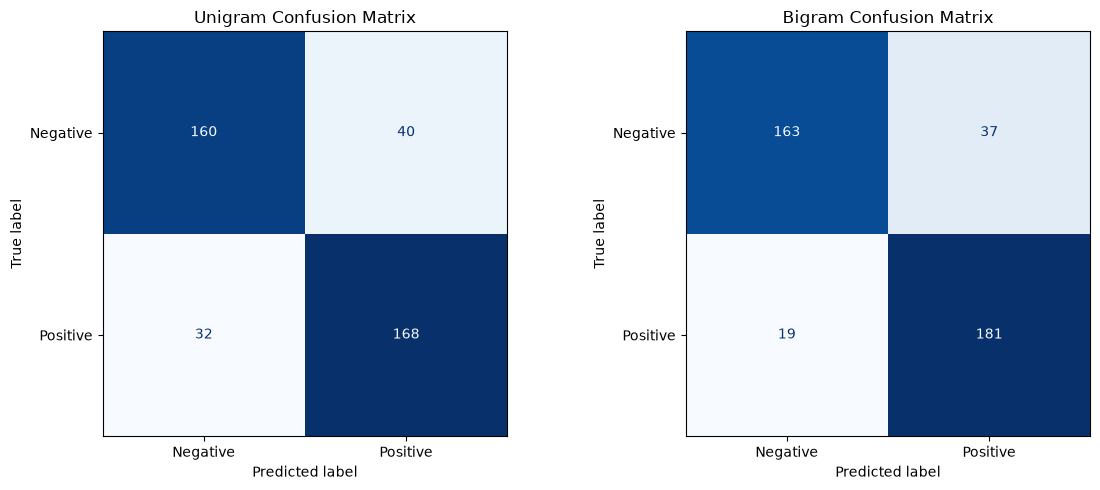

Confusion matrices saved successfully!


In [11]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create figure
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    (unigram_predictions, "Unigram", axes[0]),
    (bigram_predictions, "Bigram", axes[1])
]

# Generate confusion matrices
for data, model_name, ax in models:

    cm = confusion_matrix(
        data["true_label"],
        data["predicted_label"],
        labels=["negative", "positive"]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(f"{model_name} Confusion Matrix")

plt.tight_layout()

# Save comparison figure
plt.savefig(
    "confusion_matrices_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrices saved successfully!")
